In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Bidirectional, LSTM,
    Dense, Dropout, LayerNormalization
)
from tensorflow.keras.callbacks import ReduceLROnPlateau

np.random.seed(42)
tf.random.set_seed(42)

# Download MNIST directly
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Dataset downloaded successfully!")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Dataset downloaded successfully!


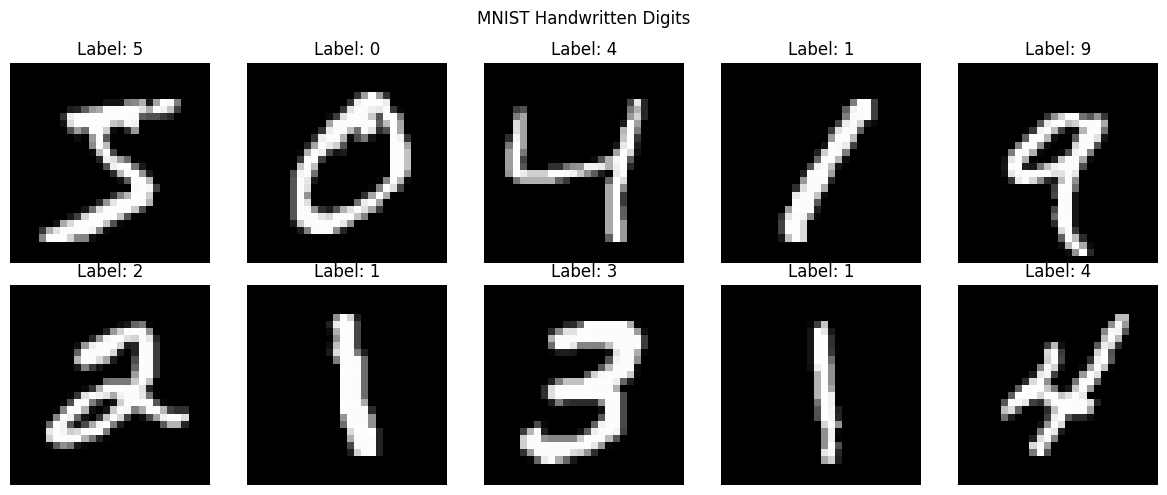

In [46]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("MNIST Handwritten Digits")
plt.tight_layout()
plt.show()

In [47]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Number of classes:", len(np.unique(y_train)))

Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)
Number of classes: 10


In [48]:
model = Sequential([
    Input(shape=(28, 28)),

    Bidirectional(
        LSTM(64, return_sequences=True)
    ),
    LayerNormalization(),
    Dropout(0.25),

    Bidirectional(LSTM(64)),
    Dropout(0.35),

    Dense(64, activation="relu"),
    Dropout(0.20),

    Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_4 (Bidirectional) │ (None, 28, 128)        │        47,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_2           │ (None, 28, 128)        │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 28, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 155,594 (607.79 KB)

 Trainable params: 155,594 (607.79 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=128,
    callbacks=[reduce_lr],
    verbose=1
)

print("Training completed successfully!")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.8239 - loss: 0.5467 - val_accuracy: 0.9565 - val_loss: 0.1386 - learning_rate: 0.0010
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9482 - loss: 0.1756 - val_accuracy: 0.9737 - val_loss: 0.0934 - learning_rate: 0.0010
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9660 - loss: 0.1180 - val_accuracy: 0.9765 - val_loss: 0.0774 - learning_rate: 0.0010
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9732 - loss: 0.0926 - val_accuracy: 0.9780 - val_loss: 0.0716 - learning_rate: 0.0010
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9768 - loss: 0.0793 - val_accuracy: 0.9845 - val_loss: 0.0532 - learning_rate: 0.0010
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9796 - loss: 0.0693 - val_accuracy: 0.9835 - val_loss: 0.0540 - learning_rate: 0.0010
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9821 - loss: 0

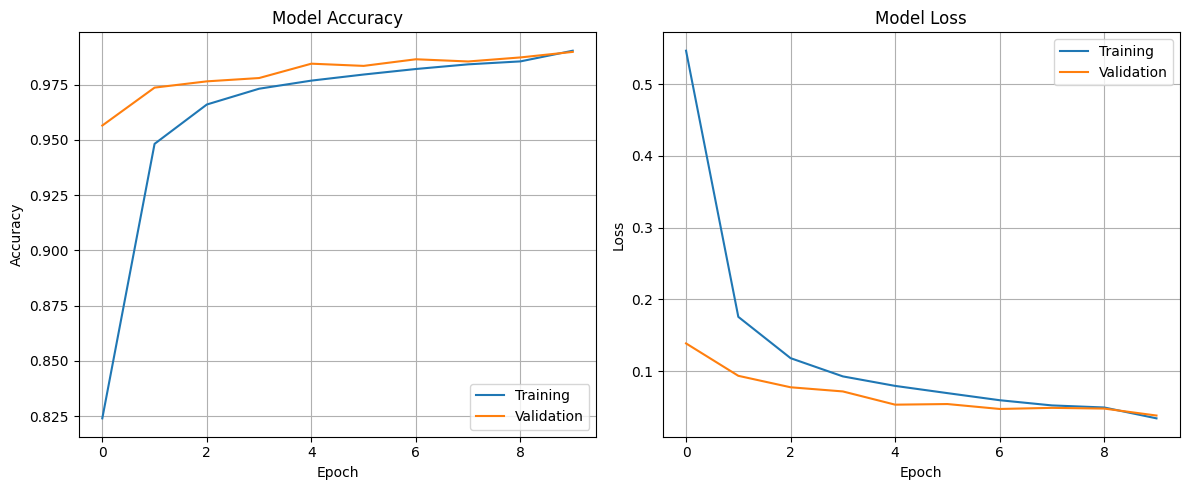

In [50]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [51]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

y_prob = model.predict(X_test, batch_size=128, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("=" * 40)
print("MNIST LSTM PROJECT RESULTS")
print("=" * 40)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
MNIST LSTM PROJECT RESULTS
Test Accuracy: 98.78%
Test Loss: 0.0412


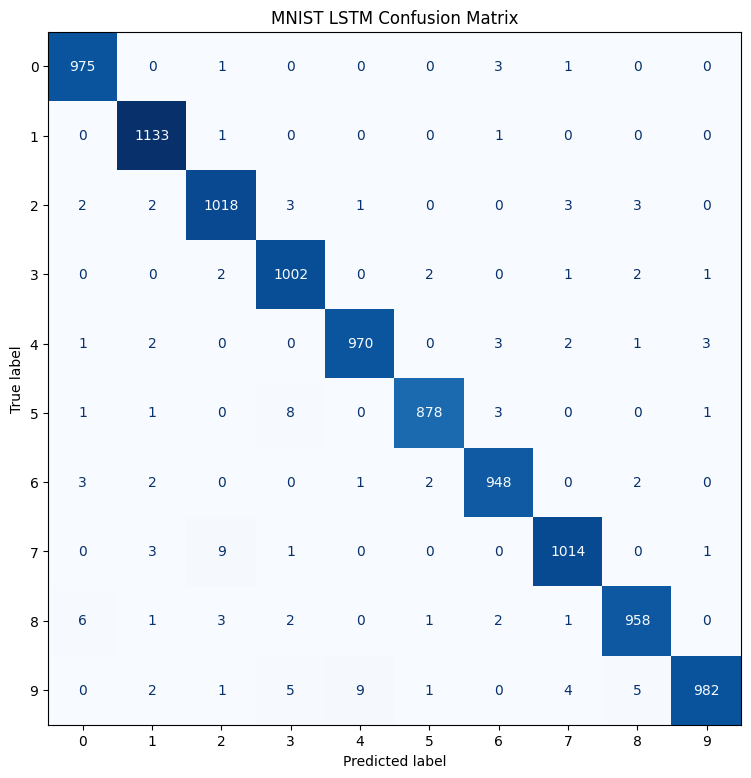

In [52]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("MNIST LSTM Confusion Matrix")
plt.show()

In [53]:
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(10),
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.99      1032
           3       0.98      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.98      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



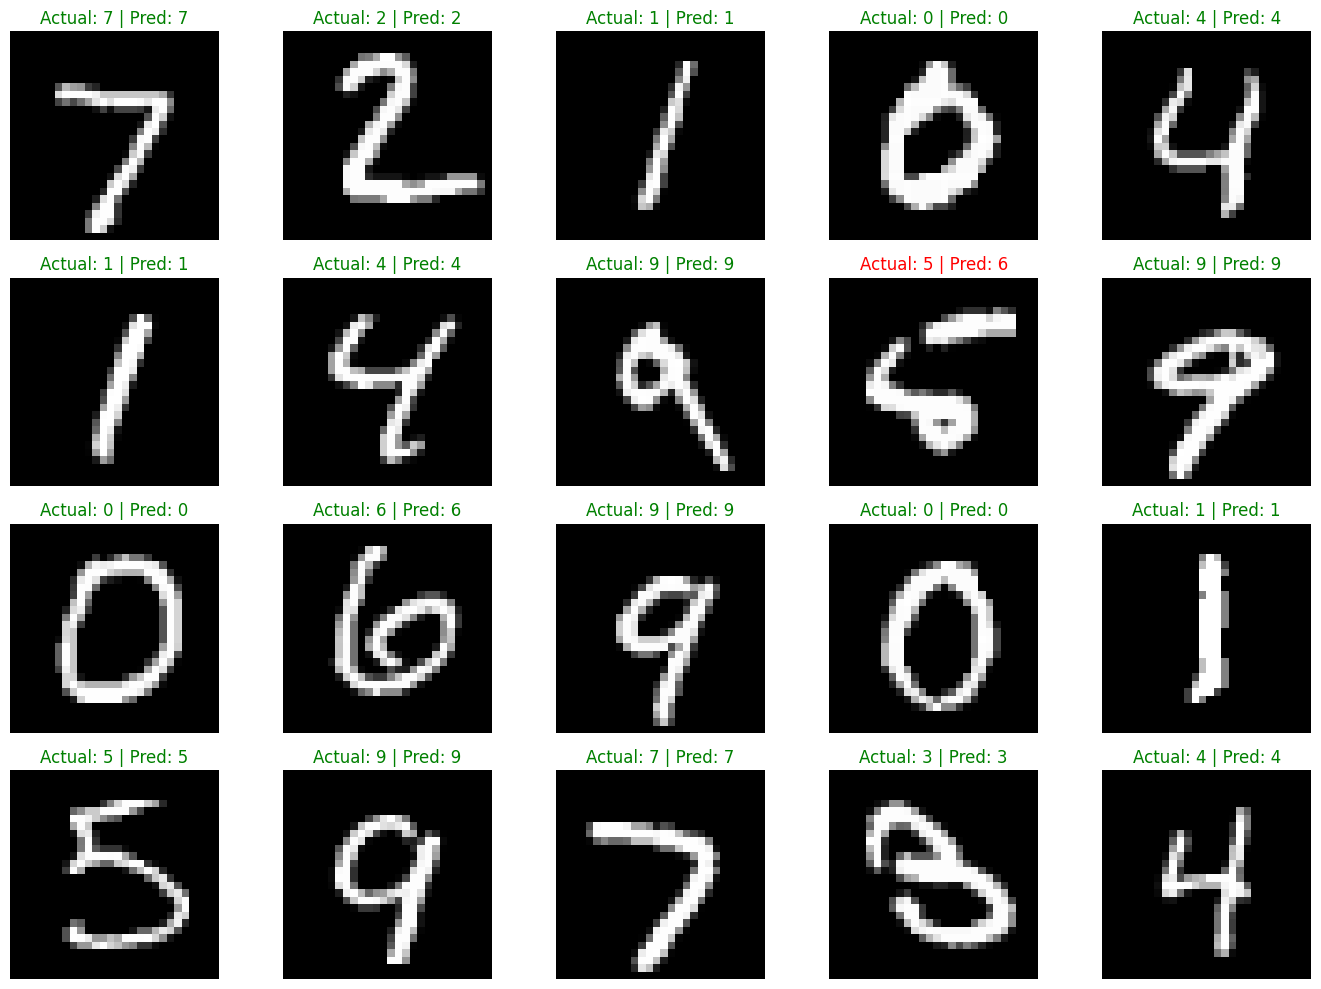

In [54]:
plt.figure(figsize=(14, 10))

for i in range(20):
    plt.subplot(4, 5, i + 1)

    plt.imshow(X_test[i], cmap="gray")

    color = "green" if y_test[i] == y_pred[i] else "red"

    plt.title(
        f"Actual: {y_test[i]} | Pred: {y_pred[i]}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [55]:
predictions_df = pd.DataFrame({
    "Actual_Digit": y_test,
    "Predicted_Digit": y_pred,
    "Correct": y_test == y_pred,
    "Confidence": np.max(y_prob, axis=1)
})

csv_path = "/content/mnist_lstm_predictions.csv"
predictions_df.to_csv(csv_path, index=False)

print("CSV saved:", csv_path)
display(predictions_df.head(10))

CSV saved: /content/mnist_lstm_predictions.csv


,Actual_Digit,Predicted_Digit,Correct,Confidence
0,7,7,True,0.999985
1,2,2,True,0.999987
2,1,1,True,0.999992
3,0,0,True,0.999973
4,4,4,True,0.999097
5,1,1,True,0.999992
6,4,4,True,0.999913
7,9,9,True,0.998995
8,5,6,False,0.872809
9,9,9,True,0.999905


In [56]:
model_path = "/content/mnist_bidirectional_lstm.keras"

model.save(model_path)

print("Model saved:", model_path)

Model saved: /content/mnist_bidirectional_lstm.keras


In [57]:
print("=" * 50)
print("MNIST BIDIRECTIONAL LSTM: FINAL SUMMARY")
print("=" * 50)

print("Dataset          : MNIST Handwritten Digits")
print("Model            : Bidirectional LSTM")
print("Classes          : 10 (digits 0-9)")
print("Training samples :", len(X_train))
print("Testing samples  :", len(X_test))
print(f"Test Accuracy    : {test_accuracy * 100:.2f}%")
print(f"Test Loss        : {test_loss:.4f}")
print("Epochs completed :", len(history.history["loss"]))
print("Predictions CSV  :", csv_path)
print("Saved model      :", model_path)
print("=" * 50)
print("MNIST LSTM PROJECT COMPLETED SUCCESSFULLY")

MNIST BIDIRECTIONAL LSTM: FINAL SUMMARY
Dataset          : MNIST Handwritten Digits
Model            : Bidirectional LSTM
Classes          : 10 (digits 0-9)
Training samples : 60000
Testing samples  : 10000
Test Accuracy    : 98.78%
Test Loss        : 0.0412
Epochs completed : 10
Predictions CSV  : /content/mnist_lstm_predictions.csv
Saved model      : /content/mnist_bidirectional_lstm.keras
MNIST LSTM PROJECT COMPLETED SUCCESSFULLY


In [58]:
from google.colab import files

files.download("/content/mnist_lstm_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>